# Paso 7 – Clustering **versión 4**: perfil situacional sin edad, sexo ni nivel de atención en salud mental (Gower)

**Dataset:** `Resultados_EnfoqueB/Dataset_final_enfoqueB.xlsx` (Paso 4B), las mismas 161 NNA que las versiones 1, 2 y 3.

**Idea de esta versión:** en el diagnóstico de variables de la v2 (sección 10 de ese notebook), `nivel_atencion_salud_mental` fue la **única** variable cuyo retiro mejoraba la silueta en todos los k candidatos (+0.048 en promedio, +0.06 con k = 6). En la v2 se decidió mantenerla por ser la única variable del área psicoemocional, y se dejó registrada la alternativa. Esta versión **evalúa esa alternativa**: parte de las 11 variables situacionales de la v2 y retira el nivel de atención en salud mental, con lo que quedan **10 variables**: legal (situación jurídica, permanencia), administrativa (estado e historial del PTI), educativa (rezago), nutricional (score de IMC y malnutrición), salud (salud física crónica, discapacidad) y procedencia.

El nivel de atención en salud mental **no desaparece del análisis**: igual que la edad, el sexo y el hogar, se usa **solo para describir** los perfiles, de modo que el área psicoemocional sigue presente en la lectura para el equipo técnico.

**Modelos:** AGNES, PAM/K-Medoids, K-Prototypes y HDBSCAN, con los mismos criterios de la v1 y la v2, para que la comparación sea directa.


# 1. Librerías y lectura del dataset de la versión

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram
from scipy.spatial.distance import squareform
from scipy.stats import chi2_contingency
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.cluster import HDBSCAN
from sklearn.manifold import MDS
from kmodes.kprototypes import KPrototypes

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

VERSION = 'v4'
VERSION_BASE = 'v2'                        # la v4 parte de las variables de la v2
RETIRADA = 'nivel_atencion_salud_mental'   # variable que se retira del modelo
BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA = BASE / 'Resultados_EnfoqueB'
X = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='dataset').set_index('id_persona')
versiones = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='versiones')
TIPOS = dict(versiones.loc[versiones['version'] == VERSION_BASE, ['variable', 'tipo_gower']].values)
TIPOS.pop(RETIRADA)
VARS = list(TIPOS)
N = len(X)
print(f'Versión {VERSION}: {N} NNA | {len(VARS)} variables (las de la {VERSION_BASE} sin {RETIRADA})')
pd.DataFrame({'tipo': TIPOS, 'vacíos': X[VARS].isna().sum(), 'valores distintos': X[VARS].nunique()})

Versión v4: 161 NNA | 10 variables (las de la v2 sin nivel_atencion_salud_mental)


,tipo,vacíos,valores distintos
ln_permanencia,num,0,103
procedencia_provincias,bin,0,2
salud_fisica_cronica,bin,0,2
presenta_discapacidad,bin,0,2
flag_rezago_escolar,bin,0,2
estado_pti,cat,0,4
situacion_juridica,cat,0,4
score_imc,ord,0,6
malnutricion_flag,bin,0,2
prop_meses_sin_pti_vigente,num,0,21


**Tipos para Gower:** `num` (numérica, normalizada por su rango), `ord` (ordinal, tratada como numérica normalizada para que la distancia entre niveles extremos sea mayor), `cat` y `bin` (coincidencia simple: 0 si son iguales, 1 si difieren). Las binarias se tratan de forma **simétrica**, es decir, que dos NNA coincidan en 0 (por ejemplo, ambas sin discapacidad) también cuenta como parecido, porque en este caso la ausencia de la condición también es informativa.

# 2. Matriz de distancias de Gower

Diferencia máxima con la librería gower: 3.27e-08
Distancias: media = 0.322 | mediana = 0.320 | mín = 0.000 | máx = 0.873


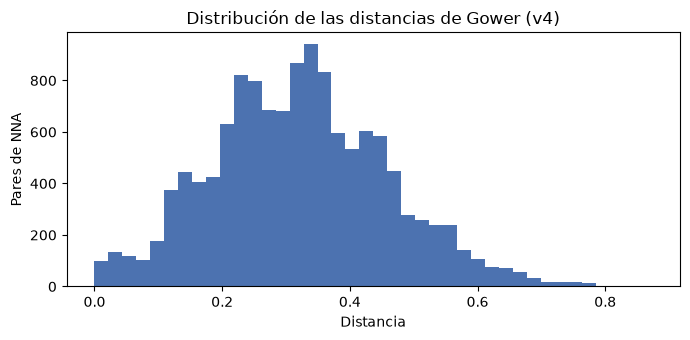

In [2]:
def gower(df, tipos):
    """Distancia de Gower. Numéricas/ordinales: |x - y| / rango. Categóricas/binarias: 0 si coinciden, 1 si no.
    Los vacíos se excluyen par a par (la distancia promedia solo las variables disponibles)."""
    n = len(df)
    num, den = np.zeros((n, n)), np.zeros((n, n))
    for c, t in tipos.items():
        x = df[c]
        ok = np.asarray(x.notna())
        valid = ok[:, None] & ok[None, :]
        if t in ('num', 'ord'):
            v = np.asarray(x, dtype=float)
            rango = np.nanmax(v) - np.nanmin(v)
            d = np.abs(v[:, None] - v[None, :]) / rango if rango > 0 else np.zeros((n, n))
        else:
            v = np.asarray(x.astype(str), dtype=object)
            d = (v[:, None] != v[None, :]).astype(float)
        num += np.where(valid, d, 0)
        den += valid
    D = num / den
    np.fill_diagonal(D, 0)
    return D


D = gower(X, TIPOS)

# Validación con la librería `gower` usada en clase (si está instalada)
try:
    import gower as gower_lib
    Xg = X[VARS].copy()
    for c in VARS:
        Xg[c] = Xg[c].astype(object) if TIPOS[c] == 'cat' else Xg[c].astype(float)
    Dlib = gower_lib.gower_matrix(Xg, cat_features=[TIPOS[c] == 'cat' for c in VARS])
    print(f'Diferencia máxima con la librería gower: {np.abs(D - Dlib).max():.2e}')
except Exception as e:
    print('No se pudo comparar con la librería gower:', e)

iu = np.triu_indices(N, 1)
print(f'Distancias: media = {D[iu].mean():.3f} | mediana = {np.median(D[iu]):.3f} | mín = {D[iu].min():.3f} | máx = {D[iu].max():.3f}')
plt.figure(figsize=(7, 3.5))
plt.hist(D[iu], bins=40, color='#4c72b0')
plt.title(f'Distribución de las distancias de Gower ({VERSION})')
plt.xlabel('Distancia')
plt.ylabel('Pares de NNA')
plt.tight_layout()
plt.show()

# 3. Funciones comunes: PAM, métricas, estabilidad y criterio de selección

- **PAM** (*Partitioning Around Medoids*) se implementa directamente (fases BUILD y SWAP), porque `scikit-learn-extra` no se instala en las versiones recientes de Python. El medoide es una NNA real que representa a su grupo.
- **Métricas internas** (todas sobre la misma matriz de Gower, para que los modelos sean comparables):
  - **Silueta** (de −1 a 1): cohesión frente a separación de cada NNA.
  - **Cohesión:** distancia media entre NNA del mismo cluster (menor es mejor).
  - **Separación:** distancia media entre NNA de clusters distintos (mayor es mejor).
  - **Dunn:** menor distancia entre clusters dividida por el mayor diámetro (mayor es mejor).
- **Estabilidad:** se remuestrea el 80 % de las NNA sin reemplazo, se vuelve a agrupar y se compara con la partición completa mediante el **ARI** (*Adjusted Rand Index*). Un ARI medio ≥ 0.75 indica una partición estable.
- **Criterio de selección de k:** el objetivo es obtener perfiles para revisiones interdisciplinarias, así que se buscan **entre 3 y 7 grupos** (2 es demasiado general y más de 7 fragmenta 161 NNA en grupos muy chicos), con un **mínimo de 8 NNA por grupo** (5 %). Entre los candidatos se elige el que maximiza el **índice combinado = silueta × ARI medio**, que premia a la vez la separación y la estabilidad.

In [3]:
def pam(D, k, max_iter=50):
    n = len(D)
    med = [int(np.argmin(D.sum(1)))]                     # BUILD: primer medoide = el más central
    for _ in range(1, k):
        dmin = D[:, med].min(1)
        ganancia = np.array([np.maximum(dmin - D[:, j], 0).sum() if j not in med else -1 for j in range(n)])
        med.append(int(np.argmax(ganancia)))
    costo = D[:, med].min(1).sum()
    for _ in range(max_iter):                            # SWAP: intercambia medoide por no medoide si baja el costo
        mejoro = False
        for i in range(k):
            for h in range(n):
                if h in med:
                    continue
                m = med.copy()
                m[i] = h
                c = D[:, m].min(1).sum()
                if c < costo - 1e-12:
                    costo, med, mejoro = c, m, True
        if not mejoro:
            break
    return np.array(med), D[:, med].argmin(1), costo


def metricas(D, lab):
    lab = np.asarray(lab)
    ks = np.unique(lab)
    mismo = lab[:, None] == lab[None, :]
    off = ~np.eye(len(D), dtype=bool)
    diam = max(D[np.ix_(lab == a, lab == a)].max() for a in ks)
    min_inter = min(D[np.ix_(lab == a, lab == b)].min() for i, a in enumerate(ks) for b in ks[i + 1:])
    return {'k': len(ks), 'silueta': silhouette_score(D, lab, metric='precomputed'),
            'cohesion_intra': D[mismo & off].mean(), 'separacion_inter': D[~mismo].mean(),
            'dunn': min_inter / diam, 'tamano_min': int(np.bincount(pd.factorize(lab)[0]).min())}


def estabilidad(ajustar, D, k, B=100, frac=0.8, semilla=0):
    """ARI medio entre la partición completa y las particiones de submuestras del 80 %."""
    rng = np.random.default_rng(semilla)
    completa = ajustar(D, k, np.arange(len(D)))
    aris = []
    for _ in range(B):
        idx = np.sort(rng.choice(len(D), int(frac * len(D)), replace=False))
        aris.append(adjusted_rand_score(completa[idx], ajustar(D[np.ix_(idx, idx)], k, idx)))
    return np.mean(aris), np.std(aris)


K_RANGO = range(2, 9)
K_CANDIDATOS = range(3, 8)
TAM_MIN = 8


def tabla_k(nombre, ajustar, B=100):
    filas = []
    for k in K_RANGO:
        lab = ajustar(D, k, np.arange(N))
        m = metricas(D, lab)
        m['ARI_medio'], m['ARI_sd'] = estabilidad(ajustar, D, k, B=B)
        filas.append(m)
    t = pd.DataFrame(filas).set_index('k')
    t['indice_combinado'] = t['silueta'] * t['ARI_medio']
    t['candidato'] = t.index.isin(K_CANDIDATOS) & (t['tamano_min'] >= TAM_MIN)
    t.insert(0, 'modelo', nombre)
    return t


def elegir_k(t):
    return int(t[t['candidato']]['indice_combinado'].idxmax())


def cramer_v(a, b):
    t = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


def eta2(cat, num):
    d = pd.DataFrame({'c': np.asarray(cat), 'n': np.asarray(num, dtype=float)}).dropna()
    m = d['n'].mean()
    return d.groupby('c')['n'].apply(lambda s: len(s) * (s.mean() - m) ** 2).sum() / ((d['n'] - m) ** 2).sum()

# 4. Modelo 1 – AGNES (jerárquico aglomerativo) sobre Gower

El método de Ward supone distancias euclidianas, así que no corresponde con Gower. Se comparan los enlaces que sí aceptan cualquier disimilitud (promedio, completo, simple y ponderado) mediante la **correlación cofenética**, que mide qué tan bien el dendrograma conserva las distancias originales.

Correlación cofenética: {'average': np.float64(0.696), 'complete': np.float64(0.596), 'single': np.float64(0.564), 'weighted': np.float64(0.577)}


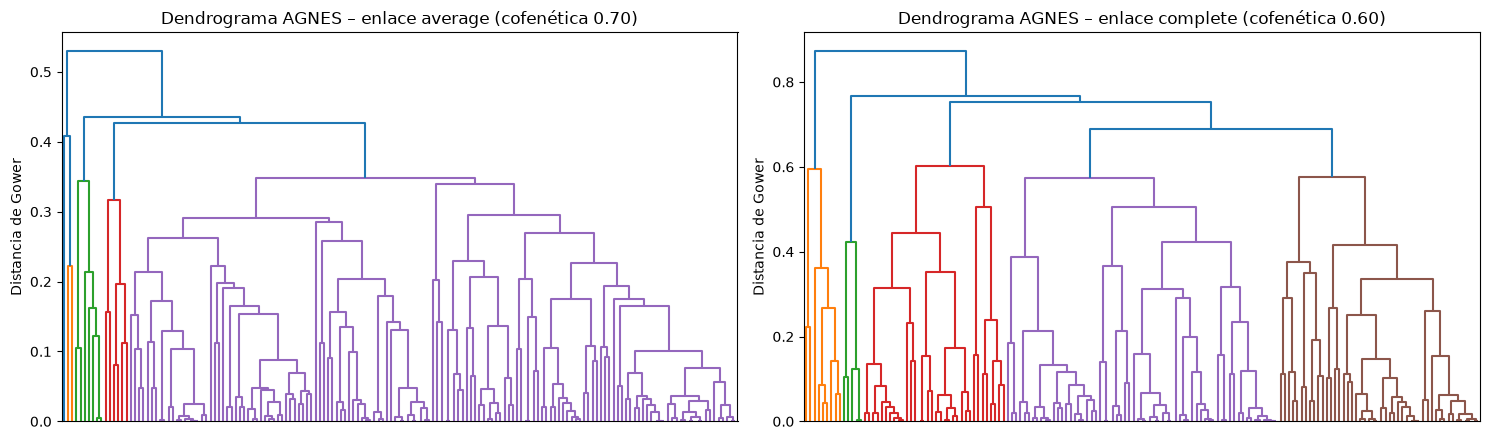

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato
k,,,,,,,,,,
2,AGNES promedio,0.385,0.314,0.530,0.240,3,0.803,0.279,0.309,False
3,AGNES promedio,0.250,0.303,0.465,0.135,3,0.562,0.275,0.141,False
4,AGNES promedio,0.224,0.292,0.451,0.135,3,0.780,0.149,0.175,False
5,AGNES promedio,0.196,0.292,0.451,0.135,1,0.673,0.258,0.132,False
6,AGNES promedio,0.275,0.237,0.380,0.170,1,0.452,0.321,0.124,False
7,AGNES promedio,0.250,0.237,0.380,0.170,1,0.547,0.311,0.137,False
8,AGNES promedio,0.218,0.232,0.379,0.170,1,0.595,0.292,0.129,False
2,AGNES completo,0.279,0.308,0.439,0.130,9,0.231,0.256,0.065,False
3,AGNES completo,0.217,0.298,0.445,0.133,5,0.195,0.171,0.042,False


In [4]:
Dc = squareform(D, checks=False)
cofe = {m: cophenet(linkage(Dc, m), Dc)[0] for m in ['average', 'complete', 'single', 'weighted']}
print('Correlación cofenética:', {m: round(v, 3) for m, v in cofe.items()})

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, m in zip(ax, ['average', 'complete']):
    dendrogram(linkage(Dc, m), ax=a, no_labels=True, color_threshold=None)
    a.set_title(f'Dendrograma AGNES – enlace {m} (cofenética {cofe[m]:.2f})')
    a.set_ylabel('Distancia de Gower')
plt.tight_layout()
plt.show()


def ajustar_agnes(metodo):
    return lambda Dm, k, idx: fcluster(linkage(squareform(Dm, checks=False), metodo), k, 'maxclust')


t_avg = tabla_k('AGNES promedio', ajustar_agnes('average'))
t_com = tabla_k('AGNES completo', ajustar_agnes('complete'))
pd.concat([t_avg, t_com]).round(3)

In [5]:
print('Tamaños de los grupos, enlace promedio:', {k: np.bincount(ajustar_agnes('average')(D, k, None))[1:].tolist() for k in (3, 4, 5)})

Tamaños de los grupos, enlace promedio: {3: [3, 7, 151], 4: [3, 7, 6, 145], 5: [2, 1, 7, 6, 145]}


**Comentario 4:** **AGNES sigue sin producir una partición útil en la v4.**
- El enlace **promedio** tiene la mayor correlación cofenética (0.70, algo mayor que en la v2), pero de nuevo **aísla atípicos**: con k = 3 deja grupos de 3, 7 y 151 NNA.
- El enlace **completo** genera en todos los k candidatos un grupo de 5 NNA o menos (por debajo del mínimo de 8) y es inestable (ARI de 0.20 a 0.53).

Ningún k de AGNES es candidato. Retirar el nivel de atención en salud mental no cambia este diagnóstico: el problema de AGNES con Gower es el encadenamiento de casos atípicos, no una variable en particular.

# 5. Modelo 2 – PAM / K-Medoids sobre Gower

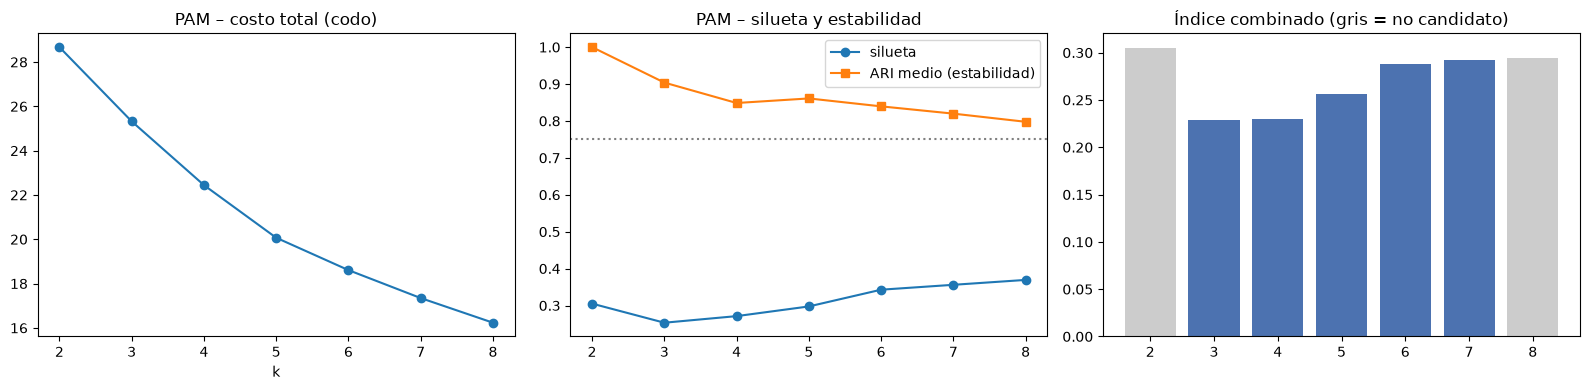

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato,costo
k,,,,,,,,,,,
2,PAM,0.305,0.266,0.378,0.132,72,1.000,0.000,0.305,False,28.673
3,PAM,0.253,0.247,0.364,0.027,38,0.904,0.167,0.229,True,25.323
4,PAM,0.271,0.220,0.357,0.119,29,0.849,0.214,0.230,True,22.445
5,PAM,0.298,0.201,0.354,0.050,25,0.861,0.138,0.256,True,20.069
6,PAM,0.343,0.182,0.353,0.157,19,0.840,0.083,0.288,True,18.608
7,PAM,0.356,0.164,0.352,0.077,10,0.820,0.109,0.292,True,17.346
8,PAM,0.369,0.157,0.350,0.077,10,0.798,0.117,0.295,False,16.234


In [6]:
ajustar_pam = lambda Dm, k, idx: pam(Dm, k)[1]
t_pam = tabla_k('PAM', ajustar_pam)
costos = {k: pam(D, k)[2] for k in K_RANGO}
t_pam['costo'] = pd.Series(costos)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(list(costos), list(costos.values()), marker='o')
ax[0].set_title('PAM – costo total (codo)')
ax[0].set_xlabel('k')
ax[1].plot(t_pam.index, t_pam['silueta'], marker='o', label='silueta')
ax[1].plot(t_pam.index, t_pam['ARI_medio'], marker='s', label='ARI medio (estabilidad)')
ax[1].axhline(0.75, color='gray', ls=':')
ax[1].set_title('PAM – silueta y estabilidad')
ax[1].legend()
ax[2].bar(t_pam.index, t_pam['indice_combinado'], color=['#4c72b0' if c else '#cccccc' for c in t_pam['candidato']])
ax[2].set_title('Índice combinado (gris = no candidato)')
plt.tight_layout()
plt.show()
t_pam.round(3)

**Comentario 5:** **PAM mejora de forma clara respecto de la v2** en todos los k candidatos:

| k | Silueta v2 | **Silueta v4** | ARI v2 | **ARI v4** |
|---|---|---|---|---|
| 3 | 0.226 | **0.253** | 0.75 | **0.90** |
| 4 | 0.243 | **0.271** | 0.75 | **0.85** |
| 5 | 0.262 | **0.298** | 0.83 | **0.86** |
| 6 | 0.282 | **0.343** | 0.77 | **0.84** |
| 7 | 0.267 | **0.356** | 0.79 | **0.82** |

La regla elige **k = 7** (índice combinado 0.292), casi empatado con **k = 6** (0.288). La diferencia es mínima, así que la elección se revisa también por interpretabilidad en la sección 12: k = 7 separa un grupo chico (10 NNA) de adolescentes con salud crónica, rezago escolar y malnutrición, que es el tipo de caso complejo que el equipo necesita identificar. A cambio, ese grupo queda en el límite (10 NNA, apenas sobre el mínimo de 8). k = 2 (ARI 1.00) solo separa PTI vigente de no vigente, y k = 8 queda fuera del rango operativo.

# 6. Modelo 3 – K-Prototypes

K-Prototypes no usa la matriz de Gower: combina la distancia euclidiana para las numéricas (llevadas a [0, 1], igual que en Gower) con la de coincidencia para las categóricas, ponderadas por γ (por defecto, la mitad de la desviación estándar media de las numéricas). Para compararlo con los demás, su silueta se calcula **sobre la misma matriz de Gower**, como en el cuaderno de ejemplo. Por su costo de cómputo, la estabilidad se estima con 30 remuestreos.

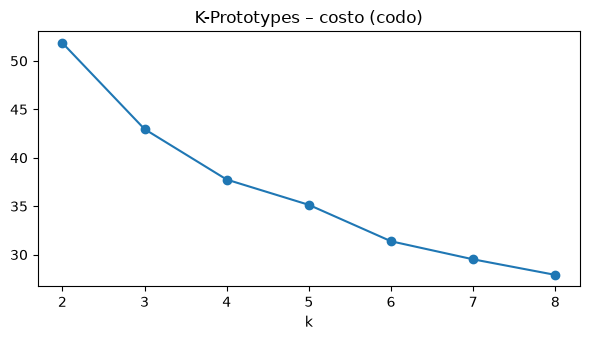

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato,costo
k,,,,,,,,,,,
2,K-Prototypes,0.224,0.285,0.363,0.032,62,0.979,0.034,0.220,False,51.855
3,K-Prototypes,0.215,0.255,0.357,0.026,40,0.914,0.110,0.196,True,42.960
4,K-Prototypes,0.181,0.247,0.351,0.034,29,0.731,0.170,0.132,True,37.749
5,K-Prototypes,0.211,0.225,0.350,0.033,12,0.719,0.074,0.151,True,35.138
6,K-Prototypes,0.248,0.205,0.349,0.035,6,0.812,0.123,0.202,False,31.379
7,K-Prototypes,0.237,0.189,0.347,0.024,11,0.747,0.095,0.177,True,29.514
8,K-Prototypes,0.219,0.188,0.343,0.024,10,0.694,0.097,0.152,False,27.907


In [7]:
cat_idx = [i for i, c in enumerate(VARS) if TIPOS[c] in ('cat', 'bin')]
Xk = X[VARS].copy()
for c in VARS:
    if TIPOS[c] in ('num', 'ord'):
        Xk[c] = (Xk[c] - Xk[c].min()) / (Xk[c].max() - Xk[c].min())
    else:
        Xk[c] = Xk[c].astype(str)
Xk_val = Xk.to_numpy(dtype=object)


def ajustar_kproto(Dm, k, idx):
    return KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42).fit_predict(Xk_val[idx], categorical=cat_idx)


t_kp = tabla_k('K-Prototypes', ajustar_kproto, B=30)
t_kp['costo'] = [KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42).fit(Xk_val, categorical=cat_idx).cost_ for k in K_RANGO]
plt.figure(figsize=(6, 3.5))
plt.plot(t_kp.index, t_kp['costo'], marker='o')
plt.title('K-Prototypes – costo (codo)')
plt.xlabel('k')
plt.tight_layout()
plt.show()
t_kp.round(3)

**Comentario 6:** K-Prototypes también mejora respecto de la v2 (silueta de 0.18 a 0.22 en los candidatos, ARI de 0.72 a 0.91), pero sigue por debajo de PAM en separación. Su mejor candidato es **k = 3** (silueta 0.215, ARI 0.91, índice 0.196). Con k = 6 genera un grupo de 6 NNA, por lo que no es candidato.

# 7. Modelo 4 – HDBSCAN (densidad) sobre Gower

HDBSCAN no necesita fijar k: busca zonas densas y deja como **ruido (−1)** a las NNA que no pertenecen a ninguna. Se prueba una grilla de `min_cluster_size` (tamaño mínimo de grupo) y `min_samples` (qué tan conservador es al declarar ruido).

In [8]:
filas = []
for mcs in [5, 8, 10, 15]:
    for ms in [None, 3, 5]:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, metric='precomputed').fit(D.copy()).labels_
        k = len(set(lab) - {-1})
        ok = lab != -1
        sil = silhouette_score(D[np.ix_(ok, ok)], lab[ok], metric='precomputed') if k > 1 else np.nan
        filas.append({'min_cluster_size': mcs, 'min_samples': ms, 'clusters': k, 'ruido_n': int((~ok).sum()),
                      'ruido_pct': round((~ok).mean() * 100, 1), 'silueta_sin_ruido': sil,
                      'tamaños': np.bincount(lab[ok]).tolist() if k else []})
t_hdb = pd.DataFrame(filas)
t_hdb.round(3)

,min_cluster_size,min_samples,clusters,ruido_n,ruido_pct,silueta_sin_ruido,tamaños
0,5,NaN,7,79,49.1,0.653,"[27, 9, 9, 16, 6, 9, 6]"
1,5,3.0,9,74,46.0,0.607,"[11, 16, 10, 6, 8, 10, 10, 11, 5]"
2,5,5.0,7,79,49.1,0.653,"[27, 9, 9, 16, 6, 9, 6]"
3,8,NaN,5,89,55.3,0.638,"[12, 9, 16, 27, 8]"
4,8,3.0,6,77,47.8,0.599,"[11, 16, 27, 10, 10, 10]"
5,8,5.0,5,79,49.1,0.528,"[27, 21, 9, 9, 16]"
6,10,NaN,2,105,65.2,0.522,"[32, 24]"
7,10,3.0,6,77,47.8,0.599,"[11, 16, 27, 10, 10, 10]"
8,10,5.0,3,74,46.0,0.428,"[30, 27, 30]"
9,15,NaN,0,161,100.0,NaN,[]


**Comentario 7:** HDBSCAN encuentra **núcleos todavía más densos** que en la v2 (silueta sin ruido de hasta **0.65**, frente a 0.54), lo que confirma que sin el nivel de atención en salud mental las situaciones legales, administrativas y nutricionales se repiten de forma más nítida. Aun así deja como ruido entre el **37 % y el 65 %** de las NNA (100 % con `min_cluster_size` = 15 y `min_samples` por defecto), así que no sirve para asignar un perfil a cada residente. Se mantiene solo como diagnóstico.

# 8. Comparación de modelos y elección

In [9]:
modelos = {'AGNES promedio': (t_avg, ajustar_agnes('average')), 'AGNES completo': (t_com, ajustar_agnes('complete')),
           'PAM': (t_pam, ajustar_pam), 'K-Prototypes': (t_kp, ajustar_kproto)}
comp = []
for nombre, (t, f) in modelos.items():
    cand = t[t['candidato']]
    if len(cand):
        k = elegir_k(t)
        comp.append(t.loc[k].to_dict() | {'modelo': nombre, 'k_elegido': k})
    else:
        comp.append({'modelo': nombre, 'k_elegido': None})
comp = pd.DataFrame(comp).set_index('modelo')[['k_elegido', 'silueta', 'cohesion_intra', 'separacion_inter', 'dunn', 'tamano_min', 'ARI_medio', 'indice_combinado']]
comp.loc['HDBSCAN (mejor de la grilla)'] = [np.nan, t_hdb['silueta_sin_ruido'].max(), np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]
comp.round(3)

,k_elegido,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,indice_combinado
modelo,,,,,,,,
AGNES promedio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AGNES completo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PAM,7.0,0.356,0.164,0.352,0.077,10.0,0.820,0.292
K-Prototypes,3.0,0.215,0.255,0.357,0.026,40.0,0.914,0.196
HDBSCAN (mejor de la grilla),NaN,0.653,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
MEJOR = comp['indice_combinado'].idxmax()
K = int(comp.loc[MEJOR, 'k_elegido'])
lab = modelos[MEJOR][1](D, K, np.arange(N))
lab = pd.factorize(pd.Series(lab).map(lambda v: v), sort=True)[0]          # etiquetas 0..K-1
X['cluster'] = lab
print(f'Modelo elegido: {MEJOR} con k = {K}')
print('Tamaños:', X['cluster'].value_counts().sort_index().to_dict())
if MEJOR == 'PAM':
    medoides = X.index[pam(D, K)[0]].tolist()
    print('Medoides (NNA representativas):', medoides)

Modelo elegido: PAM con k = 7
Tamaños: {0: 26, 1: 10, 2: 18, 3: 41, 4: 21, 5: 27, 6: 18}
Medoides (NNA representativas): ['PPA_FN_0062', 'PPA_FN_0026', 'PPA_FN_0022', 'PPA_FN_0001', 'PPA_FN_0064', 'PPA_FN_0107', 'PPA_FN_0105']


**Comentario 8:** El modelo elegido para la v4 es **PAM con k = 7**: silueta 0.356, ARI 0.82, grupo mínimo de 10 NNA e índice combinado 0.292, frente a 0.196 de K-Prototypes. Es la silueta más alta de las cuatro versiones (v1 0.203, v2 0.282, v3 0.195), aunque sigue en el rango de una estructura **moderada**. Los tamaños son 26, 10, 18, 41, 21, 27 y 18 NNA.

# 9. Contraste con la versión 2 (y la versión 1)

In [11]:
# ¿Cuánto cambia la partición al retirar el nivel de atención en salud mental?
asig_prev = {}
for v in ['v1', 'v2']:
    ruta_v = RUTA / f'Clusters_{v}.xlsx'
    if ruta_v.exists():
        asig_prev[v] = pd.read_excel(ruta_v, sheet_name='asignacion').set_index('id_persona')['cluster'].loc[X.index]
        print(f'ARI entre la partición {v} y la v4: {adjusted_rand_score(asig_prev[v], X["cluster"]):.3f}')
    else:
        print(f'Ejecute primero el notebook de la versión {v[-1]}.')

if 'v2' in asig_prev:
    print('\nTabla cruzada (filas = cluster v2, columnas = cluster v4):')
    print(pd.crosstab(asig_prev['v2'], X['cluster']))

# Asociación de cada partición con lo demográfico y con la variable retirada
filas = []
for nombre, labv in list(asig_prev.items()) + [('v4', X['cluster'])]:
    filas.append({'versión': nombre, 'V sexo': cramer_v(labv, X['sexo']), 'η edad': np.sqrt(eta2(labv, X['edad_anios'])),
                  'V hogar': cramer_v(labv, X['hogar']), 'η nivel atención salud mental': np.sqrt(eta2(labv, X[RETIRADA])),
                  'silueta en Gower v4': silhouette_score(D, labv, metric='precomputed')})
pd.DataFrame(filas).set_index('versión').round(3)


ARI entre la partición v1 y la v4: 0.478
ARI entre la partición v2 y la v4: 0.753

Tabla cruzada (filas = cluster v2, columnas = cluster v4):
cluster   0  1  2   3   4   5   6
cluster                          
0         0  1  8   0   0   2  18
1        26  0  0   0   1   3   0
2         0  5  8   0   0   0   0
3         0  2  0  41   1   0   0
4         0  2  0   0  19   1   0
5         0  0  2   0   0  21   0


,V sexo,η edad,V hogar,η nivel atención salud mental,silueta en Gower v4
versión,,,,,
v1,0.610,0.468,0.395,0.222,0.171
v2,0.160,0.382,0.304,0.303,0.315
v4,0.163,0.438,0.316,0.202,0.356


**Comentario 9:** **La v4 es, en lo esencial, la v2 con un perfil más.** El ARI entre ambas es **0.75**, mucho más alto que el de cualquier otro par de versiones (v1-v4 = 0.48; v1-v2 = 0.42). La tabla cruzada muestra qué cambia:
- Los clusters 1, 3, 4 y 5 de la v2 se conservan casi completos en los clusters **0**, **3**, **4** y **5** de la v4 (26 de 30, 41 de 44, 19 de 22 y 21 de 23).
- El cluster 0 de la v2 (provisional prolongada, sin PTI vigente y con malnutrición) se divide según el **estado del PTI**: los que tienen el PTI **vencido** pasan al cluster **6** (18 NNA) y los que **no tienen PTI** se juntan con parte del antiguo cluster 2 en el cluster **2**.
- El cluster 2 de la v2 (muy larga permanencia con salud crónica) se reparte entre el **1** (5 NNA) y el **2** (8 NNA).

La asociación con el sexo (V = 0.16) y con el hogar (V = 0.32) queda prácticamente igual que en la v2, así que la v4 tampoco depende de lo demográfico. La asociación con la edad sube un poco (η de 0.38 a 0.44).

Como se esperaba, la **asociación con el nivel de atención en salud mental baja** de η = 0.30 en la v2 a **0.20** en la v4. Es el costo de esta versión: los perfiles se separan mejor, pero dicen menos sobre el área psicoemocional, que hay que describir aparte.

# 10. Diagnóstico: ¿alguna variable impide una mejor agrupación?

Se retira cada variable de a una, se recalcula Gower y se vuelve a ajustar el modelo elegido en los k candidatos. Retirar una variable casi siempre sube un poco la silueta, porque hay menos dimensiones. Por eso solo se considera que una variable **perjudica** la agrupación si su retiro mejora la silueta de forma **consistente en todos los k** y en una magnitud apreciable (> 0.03 en promedio).

In [12]:
base_sil = {k: silhouette_score(D, modelos[MEJOR][1](D, k, np.arange(N)), metric='precomputed') for k in K_CANDIDATOS}
loo = {}
for v in VARS:
    Dv = gower(X, {c: t for c, t in TIPOS.items() if c != v})
    loo[v] = {k: silhouette_score(Dv, modelos[MEJOR][1](Dv, k, np.arange(N)), metric='precomputed') - base_sil[k] for k in K_CANDIDATOS}
loo = pd.DataFrame(loo).T
loo.columns = [f'Δsil k={k}' for k in K_CANDIDATOS]
loo['Δ promedio'] = loo.mean(axis=1)
loo['mejora en todos los k'] = (loo.iloc[:, :len(K_CANDIDATOS)] > 0).all(axis=1)
loo.sort_values('Δ promedio', ascending=False).round(3)

,Δsil k=3,Δsil k=4,Δsil k=5,Δsil k=6,Δsil k=7,Δ promedio,mejora en todos los k
ln_permanencia,0.038,0.015,0.008,0.030,0.029,0.024,True
prop_meses_sin_pti_vigente,0.064,0.019,0.031,-0.004,-0.004,0.021,False
salud_fisica_cronica,0.016,0.027,0.026,0.031,-0.006,0.019,False
presenta_discapacidad,0.012,0.016,0.016,0.019,0.020,0.017,True
procedencia_provincias,0.014,0.011,0.013,0.013,0.018,0.014,True
estado_pti,0.049,0.045,0.002,-0.018,-0.021,0.011,False
flag_rezago_escolar,-0.000,0.020,0.022,0.024,-0.012,0.011,False
score_imc,0.028,0.011,0.034,-0.018,-0.017,0.008,False
situacion_juridica,0.026,0.012,-0.018,-0.036,-0.002,-0.004,False
malnutricion_flag,0.080,0.080,-0.035,-0.068,-0.079,-0.004,False


**Comentario 10:** **Ninguna de las 10 variables restantes cumple el criterio** para considerarse perjudicial: las que mejoran la silueta en todos los k (`ln_permanencia`, `presenta_discapacidad` y `procedencia_provincias`) lo hacen en menos de 0.03 en promedio, que es lo esperable al quitar una dimensión. Las variables nutricionales y legales (`malnutricion_flag`, `situacion_juridica`, `score_imc`, `estado_pti`) **empeoran** la silueta con k = 6 y k = 7 al retirarlas, es decir, son las que sostienen la estructura. La v4 queda, por lo tanto, con un conjunto de variables en el que todas aportan a la agrupación.

# 11. Sensibilidad: NNA recuperados (INC-01 / INC-06)

En el Paso 4B se recuperaron 16 NNA con correcciones que la institución todavía tiene en revisión. Se ajusta el modelo **sin ellos** y se compara la asignación de las 145 NNA restantes con la del modelo completo.

In [13]:
sin_rec = np.asarray(X['id_recuperado'] == 'No')
lab_sin = modelos[MEJOR][1](D[np.ix_(sin_rec, sin_rec)], K, np.where(sin_rec)[0])
ari_rec = adjusted_rand_score(X.loc[sin_rec, 'cluster'], lab_sin)
print(f'ARI entre el modelo completo y el modelo sin los 16 NNA recuperados (sobre las {sin_rec.sum()} NNA comunes): {ari_rec:.3f}')
print('Distribución de los recuperados por cluster:', X.loc[~sin_rec, 'cluster'].value_counts().sort_index().to_dict())

ARI entre el modelo completo y el modelo sin los 16 NNA recuperados (sobre las 145 NNA comunes): 0.904
Distribución de los recuperados por cluster: {0: 3, 1: 1, 2: 1, 3: 4, 4: 2, 5: 4, 6: 1}


**Comentario 11:** Al excluir a los 16 NNA recuperados, las 145 restantes quedan en grupos **casi idénticos (ARI = 0.90)**. Es algo menos que en la v1 y la v2 (ARI = 1.00), porque con k = 7 hay grupos más chicos y algún medoide puede cambiar. Los recuperados se reparten en los 7 grupos (3, 1, 1, 4, 2, 4 y 1), así que su inclusión no sesga los perfiles.

# 12. Caracterización de los perfiles

In [14]:
DESCRIPTIVAS = ['nivel_atencion_salud_mental', 'edad_anios', 'sexo', 'nivel_educativo', 'hogar', 'provisional_prolongada', 'activo_al_corte', 'permanencia_cat', 'tipo_discapacidad']
imp = {}
for v in VARS + [c for c in DESCRIPTIVAS if c not in VARS]:
    es_num = TIPOS.get(v) in ('num', 'ord') or (v not in TIPOS and pd.api.types.is_numeric_dtype(X[v]) and X[v].nunique() > 2)
    imp[v] = {'asociación con el cluster': np.sqrt(eta2(X['cluster'], X[v])) if es_num else cramer_v(X['cluster'], X[v]),
              'medida': 'η' if es_num else 'V de Cramér', 'uso': 'modelo' if v in VARS else 'descriptiva'}
imp = pd.DataFrame(imp).T.sort_values('asociación con el cluster', ascending=False)
imp

,asociación con el cluster,medida,uso
malnutricion_flag,0.955396,V de Cramér,modelo
estado_pti,0.713024,V de Cramér,modelo
prop_meses_sin_pti_vigente,0.7041,η,modelo
score_imc,0.645226,η,modelo
salud_fisica_cronica,0.594846,V de Cramér,modelo
provisional_prolongada,0.589485,V de Cramér,descriptiva
situacion_juridica,0.501617,V de Cramér,modelo
flag_rezago_escolar,0.501455,V de Cramér,modelo
edad_anios,0.437695,η,descriptiva
ln_permanencia,0.429585,η,modelo


In [15]:
num_desc = ['edad_anios', 'meses_permanencia', 'nivel_atencion_salud_mental', 'score_imc', 'prop_meses_sin_pti_vigente']
perfil = X.groupby('cluster').agg(n=('cluster', 'size'), **{f'{c} (mediana)': (c, 'median') for c in num_desc})
perfil['% del total'] = (perfil['n'] / N * 100).round(1)
binarias = ['procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'flag_rezago_escolar', 'malnutricion_flag',
            'provisional_prolongada', 'activo_al_corte']
pct = X.assign(mujer=(X['sexo'] == 'F').astype(int)).groupby('cluster')[['mujer'] + binarias].mean().mul(100).round(0)
pct.columns = [f'% {c}' for c in pct.columns]
pd.concat([perfil.round(2), pct], axis=1).T

cluster,0,1,2,3,4,5,6
n,26.00,10.00,18.00,41.00,21.0,27.00,18.00
edad_anios (mediana),10.16,15.73,12.54,8.35,13.5,7.48,8.04
meses_permanencia (mediana),70.85,115.50,71.25,38.90,115.5,39.00,39.00
nivel_atencion_salud_mental (mediana),2.00,3.00,2.00,2.00,1.0,2.00,2.00
score_imc (mediana),0.00,0.00,2.00,2.00,0.0,0.00,2.00
prop_meses_sin_pti_vigente (mediana),0.00,0.87,1.00,0.25,0.9,1.00,0.97
% del total,16.10,6.20,11.20,25.50,13.0,16.80,11.20
% mujer,58.00,50.00,56.00,39.00,38.0,37.00,44.00
% procedencia_provincias,19.00,20.00,0.00,7.00,0.0,11.00,22.00
% salud_fisica_cronica,8.00,90.00,28.00,5.00,14.0,4.00,6.00


In [16]:
for c in ['situacion_juridica', 'estado_pti', 'nivel_atencion_salud_mental', 'nivel_educativo', 'edad_cat', 'hogar']:
    print(f'\n{c} (% dentro de cada cluster)')
    print((pd.crosstab(X['cluster'], X[c], normalize='index') * 100).round(0).to_string())


situacion_juridica (% dentro de cada cluster)
situacion_juridica  1 Tutela / Medida judicial firme  2 Acogimiento residencial formal  3 Investigacion tutelar / Medida provisional  4 Sin definir / En observacion
cluster                                                                                                                                                             
0                                                0.0                               4.0                                          96.0                             0.0
1                                               60.0                               0.0                                          40.0                             0.0
2                                               22.0                              11.0                                          61.0                             6.0
3                                                2.0                              10.0                                          

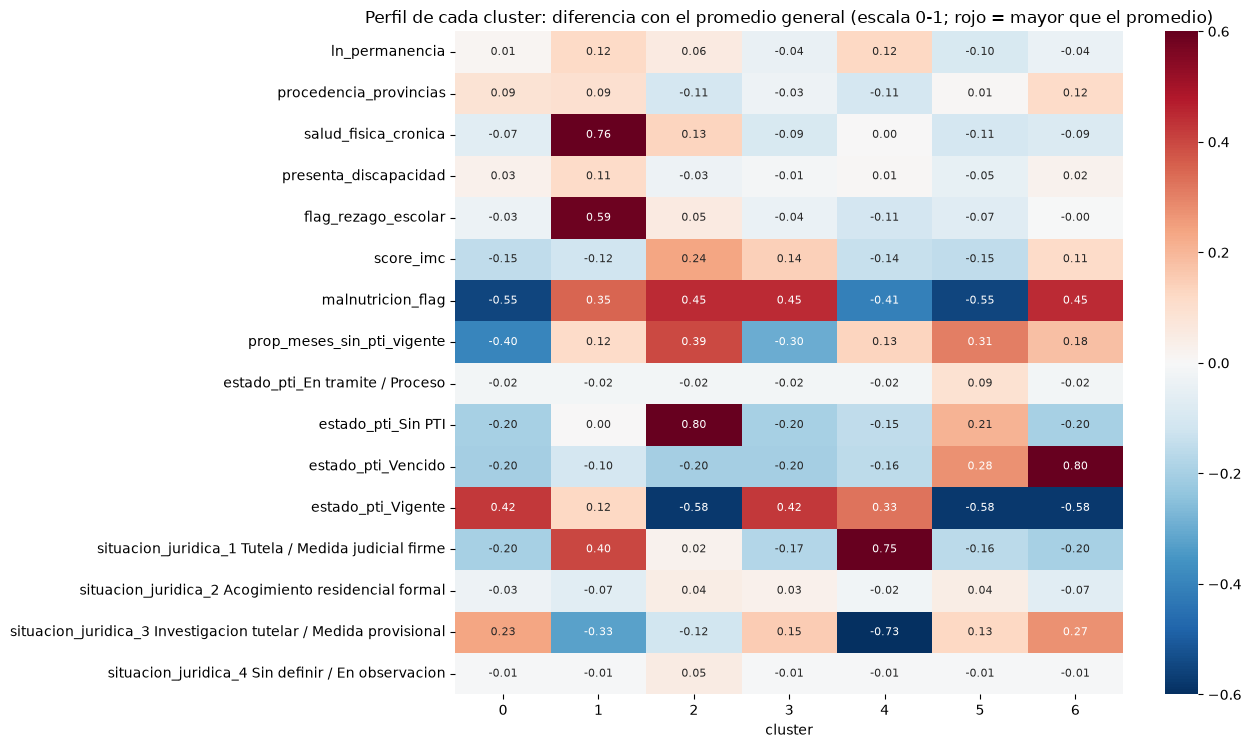

In [17]:
# Mapa de calor: diferencia de cada cluster respecto del total (variables del modelo, codificadas)
enc = pd.get_dummies(X[VARS].astype({c: str for c in VARS if TIPOS[c] == 'cat'}), dtype=float)
enc = (enc - enc.min()) / (enc.max() - enc.min())
dif = enc.groupby(X['cluster']).mean() - enc.mean()
plt.figure(figsize=(1.3 * K + 4, 0.38 * dif.shape[1] + 1.5))
sns.heatmap(dif.T, cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6, annot=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Perfil de cada cluster: diferencia con el promedio general (escala 0-1; rojo = mayor que el promedio)')
plt.xlabel('cluster')
plt.tight_layout()
plt.show()

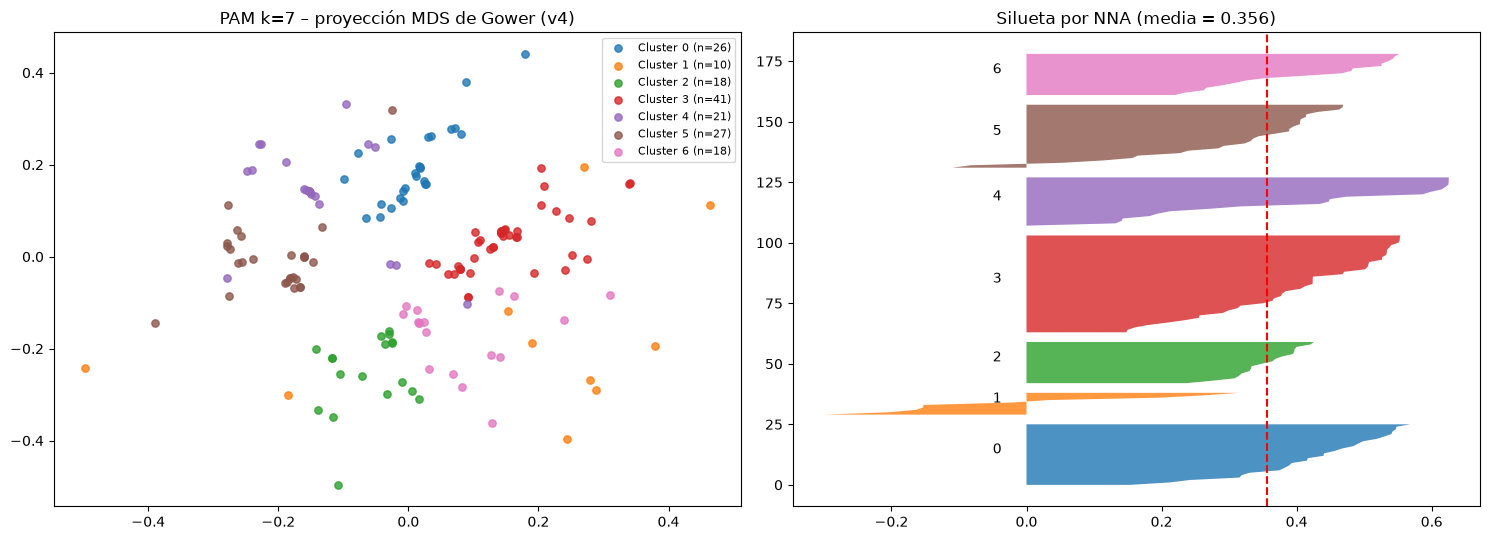

Silueta media por cluster: {0: 0.424, 1: -0.018, 2: 0.352, 3: 0.401, 4: 0.396, 5: 0.3, 6: 0.407}


In [18]:
coords = MDS(n_components=2, dissimilarity='precomputed', random_state=42, n_init=4).fit_transform(D)
sil_i = silhouette_samples(D, X['cluster'], metric='precomputed')
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for c in range(K):
    m = (X['cluster'] == c).values
    ax[0].scatter(coords[m, 0], coords[m, 1], s=28, alpha=.8, label=f'Cluster {c} (n={m.sum()})')
ax[0].set_title(f'{MEJOR} k={K} – proyección MDS de Gower ({VERSION})')
ax[0].legend(fontsize=8)
y0 = 0
for c in range(K):
    s = np.sort(sil_i[X['cluster'] == c])
    ax[1].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=.8)
    ax[1].text(-0.05, y0 + len(s) / 2, str(c))
    y0 += len(s) + 3
ax[1].axvline(sil_i.mean(), color='red', ls='--')
ax[1].set_title(f'Silueta por NNA (media = {sil_i.mean():.3f})')
plt.tight_layout()
plt.show()
print('Silueta media por cluster:', pd.Series(sil_i).groupby(X['cluster'].values).mean().round(3).to_dict())

**Comentario 12 – perfiles.** Las variables que más distinguen a los perfiles son la **malnutrición** (V = 0.96), el **estado del PTI** (V = 0.71), el **historial del PTI** (η = 0.70), el score de IMC (η = 0.65), la salud física crónica (V = 0.59) y la **provisional prolongada** (V = 0.59, que no entró al modelo y aun así queda bien separada). El rezago escolar gana peso respecto de la v2 (V de 0.17 a 0.50) porque ahora define al perfil 1. El sexo prácticamente no participa (V = 0.16) y el nivel de atención en salud mental, ya como descriptiva, tiene una asociación baja (η = 0.20).

| Perfil | n (%) | Situación legal | PTI | Nutrición y salud | Salud mental (descriptiva) | Otros rasgos |
|---|---|---|---|---|---|---|
| **0 – Provisional prolongada con PTI vigente, sin alerta nutricional** | 26 (16 %) | Provisional 96 % (prolongada 88 %) | **Vigente 100 %** | Sin malnutrición (0 %) | Acompañamiento básico 50 % | 10.2 años, 5.9 años en el CAR; 58 % mujeres |
| **1 – Adolescentes con salud crónica, rezago escolar y malnutrición** | 10 (6 %) | Firme 60 %, provisional 40 % | Vigente 70 %, sin PTI 20 % | **Salud crónica 90 %, malnutrición 90 %**, discapacidad 20 % | **Atención especializada externa 50 %** | **15.7 años, 9.6 años en el CAR, rezago 70 %**; Miguel Echenique 50 %, Tomás Valle 40 % |
| **2 – Sin PTI elaborado y con malnutrición** | 18 (11 %) | Provisional 61 %, firme 22 % | **Sin PTI 100 %** | **Malnutrición 100 %**, salud crónica 28 % | Repartido | 12.5 años, 5.9 años en el CAR; 28 % mayores de 17 |
| **3 – PTI vigente con alerta nutricional** | 41 (25 %) | Provisional 88 % | **Vigente 100 %** | **Malnutrición 100 %** (mediana = sobrepeso) | Acompañamiento básico 44 % | 8.4 años, 3.2 años en el CAR |
| **4 – Adolescentes con medida firme y larga permanencia** | 21 (13 %) | **Firme 95 %** | Vigente 90 % (regularizado recién: sin vigente en 90 % de su historial) | Sin alerta (14 %) | **Sin atención 52 %** (mediana = 1) | 13.5 años, 9.6 años en el CAR; 52 % de Matogroso hombres |
| **5 – Niñez sin PTI vigente y sin alerta nutricional** | 27 (17 %) | Provisional 85 % | **Vencido 48 %, sin PTI 41 %, en trámite 11 %** | Sin alerta (0 %) | Sin atención 44 %, terapia continua 33 % | **7.5 años**, 3.2 años en el CAR; **41 % egresó durante el periodo** |
| **6 – Provisional prolongada con PTI vencido y malnutrición** | 18 (11 %) | **Provisional 100 % (prolongada 100 %)** | **Vencido 100 %** | **Malnutrición 100 %** | Acompañamiento básico 61 % | 8.0 años, 3.2 años en el CAR; 100 % activos al corte |

**Lectura frente a la v2:** los perfiles 0, 3, 4 y 5 corresponden a los perfiles 1, 3, 4 y 5 de la v2. La novedad es que el antiguo perfil "provisional prolongada, sin PTI vigente y con malnutrición" se separa en dos situaciones administrativas distintas: **PTI vencido** (perfil 6, que requiere **actualizar** el plan) y **sin PTI** (perfil 2, que requiere **elaborarlo**). Además, los casos de salud crónica con rezago escolar forman su propio perfil (1).

**Advertencia sobre el perfil 1:** es el único con **silueta media negativa (−0.02)**: sus 10 NNA están, en promedio, tan cerca de otros grupos como del suyo. Es un grupo de casos complejos y heterogéneos que debe revisarse caso por caso. Los perfiles 0, 3, 4 y 6 son los más nítidos (silueta de 0.40 a 0.42).

# 13. Guardado

In [19]:
salida = X[['id_original', 'cluster'] + VARS + [c for c in DESCRIPTIVAS if c not in VARS]].copy()
salida['silueta_individual'] = sil_i.round(3)
resumen_modelos = pd.concat([t_avg, t_com, t_pam, t_kp])
with pd.ExcelWriter(RUTA / f'Clusters_{VERSION}.xlsx') as w:
    salida.reset_index().to_excel(w, sheet_name='asignacion', index=False)
    resumen_modelos.reset_index().to_excel(w, sheet_name='metricas_por_k', index=False)
    comp.reset_index().to_excel(w, sheet_name='comparacion_modelos', index=False)
    t_hdb.to_excel(w, sheet_name='hdbscan', index=False)
    loo.reset_index().to_excel(w, sheet_name='diagnostico_variables', index=False)
    imp.reset_index().to_excel(w, sheet_name='importancia', index=False)
    pd.DataFrame(filas).to_excel(w, sheet_name='contraste_versiones', index=False)
print('Guardado:', (RUTA / f'Clusters_{VERSION}.xlsx').relative_to(BASE))

Guardado: Resultados_EnfoqueB\Clusters_v4.xlsx


**Comentario 13:** La asignación de la v4 y sus métricas se guardan en `Resultados_EnfoqueB/Clusters_v4.xlsx` (incluye la hoja `contraste_versiones`). **Resumen de la v4:** al retirar el nivel de atención en salud mental, PAM con k = 7 da **la mejor separación (silueta 0.36) y una estabilidad mayor que la de la v2 (ARI 0.82 frente a 0.77)**, con perfiles muy parecidos a los de la v2 (ARI 0.75) y un poco más finos en lo administrativo (PTI vencido frente a sin PTI). El costo es que el área psicoemocional deja de participar en la formación de los grupos y solo se describe. La validación de los cuatro modelos (v1 a v4) con datos de prueba y estabilidad está en el notebook `Paso 8 - Validacion de los modelos de clustering.ipynb`.